> **Portfolio summary:** A Value / Quality / Momentum / Low-Vol factor tilt on the Swiss SMI, tested out of sample against 1/N (group project).
>
> [Project README](README.md) · [Back to the portfolio](../README.md)

# Factor Equity Investment Strategy
**Simplified L&G multifactor approach on 20 SMI (Swiss Market Index) stocks**

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
from scipy.stats import rankdata

# ── universe: 20 SMI (Swiss Market Index) stocks
TICKERS = [
    'NESN.SW',   # Nestlé
    'NOVN.SW',   # Novartis
    'RO.SW',     # Roche (ticker changed from ROG.SW)
    'UBSG.SW',   # UBS
    'ABBN.SW',   # ABB
    'ZURN.SW',   # Zurich Insurance
    'SIKA.SW',   # Sika
    'LONN.SW',   # Lonza
    'GIVN.SW',   # Givaudan
    'PGHN.SW',   # Partners Group
    'SCMN.SW',   # Swisscom
    'SREN.SW',   # Swiss Re
    'GEBN.SW',   # Geberit
    'SLHN.SW',   # Swiss Life
    'HOLN.SW',   # Holcim
    'KNIN.SW',   # Kuehne+Nagel
    'LOGN.SW',   # Logitech
    'BAER.SW',   # Julius Baer
    'SOON.SW',   # Sonova
    'CFR.SW',    # Richemont
]

# 5-year window: 3y in-sample to estimate scores, 2y out-of-sample to test
IS_END = '2024-04-30'

raw = yf.download(TICKERS, start='2019-04-01', end='2026-04-30',
                  auto_adjust=True, progress=False)['Close']
raw = raw.dropna(axis=1, thresh=int(0.9*len(raw))).ffill().dropna()
tickers = list(raw.columns)

monthly = raw.resample('ME').last()
ret     = monthly.pct_change().dropna()
ret_is  = ret.loc[:IS_END]
ret_oos = ret.loc[IS_END:]

print(f'{len(tickers)} tickers  |  '
      f'In-sample: {ret_is.index[0].date()} - {ret_is.index[-1].date()} ({len(ret_is)} months)  |  '
      f'OOS: {ret_oos.index[0].date()} - {ret_oos.index[-1].date()} ({len(ret_oos)} months)')
print('Tickers:', ', '.join(tickers))

## Compute factor signals

**Scoring rule:** convert each raw signal to a cross-sectional percentile rank (0 = worst, 100 = best). Higher is always better.

In [2]:
records = []
for t in tickers:
    info = yf.Ticker(t).info
    p    = raw.loc[:IS_END, t].dropna()
    m    = ret_is[t].dropna()

    # VALUE: Book-to-Price = 1 / Price-to-Book  (higher is better)
    pb  = info.get('priceToBook', np.nan)
    btp = 1/pb if pb and pb > 0 else np.nan

    # QUALITY: Return on Equity  (higher is better)
    roe = info.get('returnOnEquity', np.nan)

    # MOMENTUM: 11-month risk-adjusted return, skipping the last month
    if len(p) >= 252:
        r_window = p.pct_change().dropna().iloc[-252:-21]
        raw_mom  = p.iloc[-21] / p.iloc[-252] - 1
        vol_mom  = r_window.std() * np.sqrt(252)
        mom = raw_mom / vol_mom if vol_mom > 0 else np.nan
    else:
        mom = np.nan

    # LOW VOLATILITY: downside semi-deviation (negated so higher = better)
    neg = m[m < 0]
    low_vol = -neg.std() * np.sqrt(12) if len(neg) >= 6 else np.nan

    records.append(dict(ticker=t, Value=btp, Quality=roe, Momentum=mom, Low_Vol=low_vol,
                        market_cap=info.get('marketCap', np.nan)))

fund = pd.DataFrame(records).set_index('ticker')

out = fund[['Value', 'Quality', 'Momentum', 'Low_Vol']].copy()
out.insert(0, 'Market Cap (CHFbn)', fund['market_cap'] / 1e9)
print(out.round(4).to_string())

         Market Cap (CHFbn)   Value  Quality  Momentum  Low_Vol
ticker                                                         
ABBN.SW            147.2653  0.0781   0.3355    1.8002  -0.1329
BAER.SW             13.7101  0.5272   0.1087   -0.5938  -0.2116
CFR.SW              91.1307  0.2232   0.1813   -0.1654  -0.1462
GEBN.SW             16.6188  0.0913      NaN    0.1915  -0.1315
GIVN.SW             24.7804  0.1831   0.2342    1.5757  -0.1578
HOLN.SW             40.3228  0.3813   0.0209    2.5279  -0.1717
KNIN.SW             20.5811  0.1197   0.3228   -0.0366  -0.1377
LOGN.SW             11.3367  0.1525   0.3278    1.4490  -0.1468
LONN.SW             32.7989  0.2413   0.1048   -0.0801  -0.2040
NESN.SW            199.5785  0.1644   0.2653   -1.1587  -0.0810
NOVN.SW            225.1167  0.1612   0.3493    0.1102  -0.1113
PGHN.SW             22.7201  0.0963   0.5480    2.0934  -0.1835
ROG.SW             256.4276  0.1318   0.3727   -0.9330  -0.0873
SCMN.SW             34.9663  0.3191   0.

## Multi-factor score (equal weighting)

Each stock's multi-factor score is the simple average of its four percentile scores.

In [3]:
FACTOR_COLS = ['Value', 'Quality', 'Momentum', 'Low_Vol']

def pct_rank(s):
    v = s.dropna()
    ranks = pd.Series(100 * rankdata(v) / len(v), index=v.index)
    return ranks.reindex(s.index)

scores = fund[FACTOR_COLS].apply(pct_rank)
scores = scores[scores.notna().sum(axis=1) >= 3].copy().fillna(50)
universe = list(scores.index)

scores['MF'] = scores[FACTOR_COLS].mean(axis=1)

print(f'Investable universe: {len(universe)} stocks\n')
print(scores[['MF'] + FACTOR_COLS].sort_values('MF', ascending=False).round(1))

Investable universe: 20 stocks

           MF  Value  Quality  Momentum  Low_Vol
ticker                                          
ZURN.SW  69.5   65.0     63.2      65.0     85.0
SREN.SW  66.8   95.0     47.4      80.0     45.0
UBSG.SW  66.4  100.0     10.5      95.0     60.0
NOVN.SW  62.4   35.0     89.5      45.0     80.0
ABBN.SW  61.1    5.0     84.2      85.0     70.0
PGHN.SW  57.5   15.0    100.0      90.0     25.0
LOGN.SW  57.2   30.0     78.9      70.0     50.0
HOLN.SW  55.1   85.0      5.3     100.0     30.0
ROG.SW   54.9   25.0     94.7      10.0     90.0
GIVN.SW  54.5   45.0     57.9      75.0     40.0
NESN.SW  53.4   40.0     68.4       5.0    100.0
SCMN.SW  51.4   80.0     15.8      15.0     95.0
KNIN.SW  49.7   20.0     73.7      40.0     65.0
SIKA.SW  49.1   75.0     31.6      55.0     35.0
SLHN.SW  46.7   70.0     36.8      60.0     20.0
GEBN.SW  46.2   10.0     50.0      50.0     75.0
CFR.SW   44.3   50.0     42.1      30.0     55.0
BAER.SW  36.6   90.0     26.3      20

## Construct tilted portfolio (unconstrained)

Benchmark = equal-weight (1/N).  
Tilted weights are proportional to the multi-factor score — no constraints on sector, security, or tracking error.

In [4]:
N = len(universe)
ret_oos = ret_oos[universe]

# Benchmark: equal weight
w_eq = pd.Series(1/N, index=universe)

# Tilted portfolio: weights proportional to MF score
mf = scores.loc[universe, 'MF']
w_tilt = mf / mf.sum()

# Display weights side by side
weights = pd.DataFrame({'Equal Weight': w_eq, 'Tilted Weight': w_tilt,
                         'Active Weight': w_tilt - w_eq,
                         'MF Score': mf}).sort_values('MF Score', ascending=False)
print(weights.round(4).to_string())
print(f'\nTilted weights sum: {w_tilt.sum():.4f}')
print(f'Max weight: {w_tilt.max():.2%}  |  Min weight: {w_tilt.min():.2%}')

         Equal Weight  Tilted Weight  Active Weight  MF Score
ZURN.SW          0.05         0.0662         0.0162   69.5395
SREN.SW          0.05         0.0637         0.0137   66.8421
UBSG.SW          0.05         0.0632         0.0132   66.3816
NOVN.SW          0.05         0.0594         0.0094   62.3684
ABBN.SW          0.05         0.0581         0.0081   61.0526
PGHN.SW          0.05         0.0548         0.0048   57.5000
LOGN.SW          0.05         0.0545         0.0045   57.2368
HOLN.SW          0.05         0.0524         0.0024   55.0658
ROG.SW           0.05         0.0523         0.0023   54.9342
GIVN.SW          0.05         0.0519         0.0019   54.4737
NESN.SW          0.05         0.0508         0.0008   53.3553
SCMN.SW          0.05         0.0490        -0.0010   51.4474
KNIN.SW          0.05         0.0473        -0.0027   49.6711
SIKA.SW          0.05         0.0468        -0.0032   49.1447
SLHN.SW          0.05         0.0445        -0.0055   46.7105
GEBN.SW 

## Out-of-sample performance evaluation

In [ ]:
# Portfolio returns (static weights, no rebalancing)
r_eq   = ret_oos.dot(w_eq)
r_tilt = ret_oos.dot(w_tilt)

# Cumulative wealth
cum_eq   = (1 + r_eq).cumprod()
cum_tilt = (1 + r_tilt).cumprod()

# ── Performance metrics
def perf_metrics(r, name):
    ann_ret  = (1 + r.mean())**12 - 1
    ann_vol  = r.std() * np.sqrt(12)
    sharpe   = ann_ret / ann_vol if ann_vol > 0 else np.nan
    cum      = (1 + r).cumprod()
    drawdown = cum / cum.cummax() - 1
    max_dd   = drawdown.min()
    calmar   = ann_ret / abs(max_dd) if max_dd != 0 else np.nan
    total    = cum.iloc[-1] - 1
    return pd.Series({'Total Return': total, 'Ann. Return': ann_ret,
                      'Ann. Volatility': ann_vol, 'Sharpe Ratio': sharpe,
                      'Max Drawdown': max_dd, 'Calmar Ratio': calmar}, name=name)

perf = pd.DataFrame([perf_metrics(r_eq, '1/N Benchmark'),
                      perf_metrics(r_tilt, 'Tilted Portfolio')])

# Tracking error
te = (r_tilt - r_eq).std() * np.sqrt(12)
print(perf.round(4).to_string())
print(f'\nTracking Error (annualised): {te:.2%}')

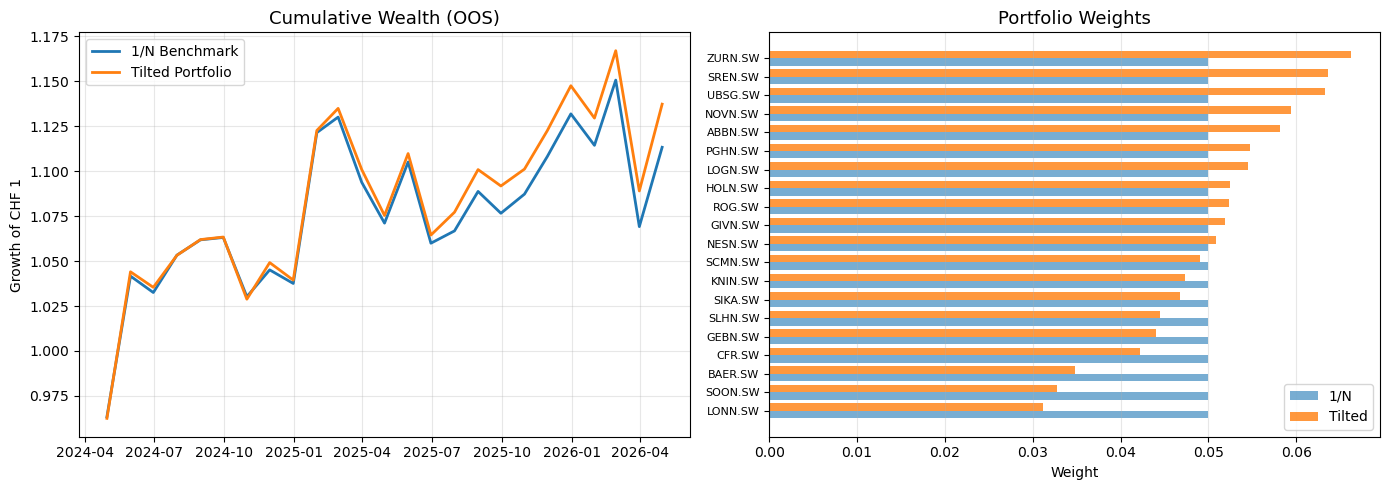

In [6]:
# ── Cumulative performance chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: cumulative wealth
ax = axes[0]
ax.plot(cum_eq.index, cum_eq.values, label='1/N Benchmark', linewidth=2)
ax.plot(cum_tilt.index, cum_tilt.values, label='Tilted Portfolio', linewidth=2)
ax.set_title('Cumulative Wealth (OOS)', fontsize=13)
ax.set_ylabel('Growth of CHF 1')
ax.legend()
ax.grid(alpha=0.3)

# Right: weight comparison
ax = axes[1]
sorted_w = weights.sort_values('MF Score')
y = range(len(sorted_w))
ax.barh(y, sorted_w['Equal Weight'], height=0.4, label='1/N', alpha=0.6)
ax.barh([i+0.4 for i in y], sorted_w['Tilted Weight'], height=0.4, label='Tilted', alpha=0.8)
ax.set_yticks([i+0.2 for i in y])
ax.set_yticklabels(sorted_w.index, fontsize=8)
ax.set_title('Portfolio Weights', fontsize=13)
ax.set_xlabel('Weight')
ax.legend()
ax.grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

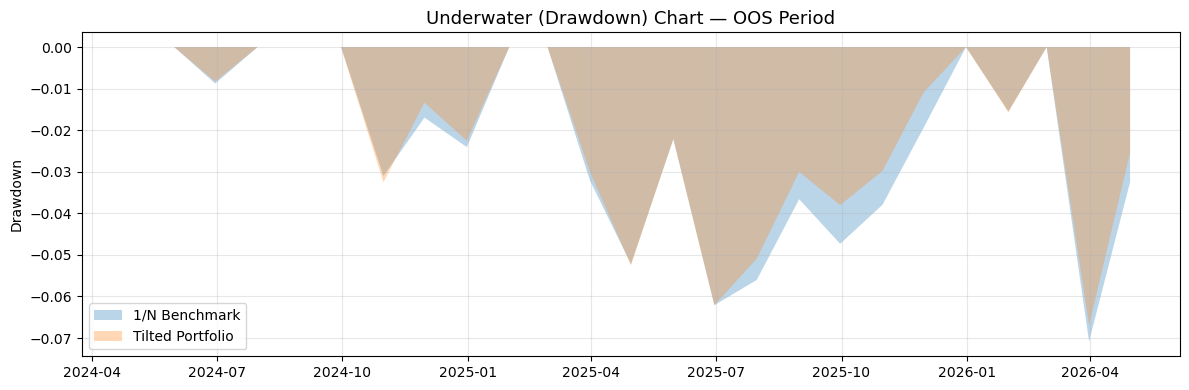

In [7]:
# ── Drawdown chart
dd_eq   = cum_eq / cum_eq.cummax() - 1
dd_tilt = cum_tilt / cum_tilt.cummax() - 1

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(dd_eq.index, dd_eq.values, alpha=0.3, label='1/N Benchmark')
ax.fill_between(dd_tilt.index, dd_tilt.values, alpha=0.3, label='Tilted Portfolio')
ax.set_title('Underwater (Drawdown) Chart — OOS Period', fontsize=13)
ax.set_ylabel('Drawdown')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# ── Factor contribution analysis
# Show how each factor's tilt contributed to active return
print('=== Factor Score Summary ===')
print(scores[FACTOR_COLS + ['MF']].describe().round(1))

print('\n=== Correlation between factor scores ===')
print(scores[FACTOR_COLS].corr().round(2))

=== Factor Score Summary ===
       Value  Quality  Momentum  Low_Vol    MF
count   20.0     20.0      20.0     20.0  20.0
mean    52.5     52.5      52.5     52.5  52.5
std     29.6     28.8      29.6     29.6  10.4
min      5.0      5.3       5.0      5.0  32.8
25%     28.8     30.3      28.8     28.8  46.6
50%     52.5     51.3      52.5     52.5  53.9
75%     76.2     75.0      76.2     76.2  58.4
max    100.0    100.0     100.0    100.0  69.5

=== Correlation between factor scores ===
          Value  Quality  Momentum  Low_Vol
Value      1.00    -0.81      0.09    -0.31
Quality   -0.81     1.00     -0.05     0.33
Momentum   0.09    -0.05      1.00    -0.25
Low_Vol   -0.31     0.33     -0.25     1.00

In [9]:
# ── Monthly active return breakdown
active = r_tilt - r_eq
print(f'Mean monthly active return: {active.mean():.4%}')
print(f'Annualised active return:   {active.mean()*12:.2%}')
print(f'Information Ratio:          {active.mean()/active.std()*np.sqrt(12):.2f}')
print(f'% months outperforming 1/N: {(active > 0).mean():.0%}')

Mean monthly active return: 0.0864%
Annualised active return:   1.04%
Information Ratio:          1.30
% months outperforming 1/N: 68%